<div style="background:linear-gradient(135deg,#0f3d6e,#1f6fb2);color:#ffffff;padding:22px 26px;border-radius:8px;">
<div style="font-size:13px;letter-spacing:1.5px;text-transform:uppercase;opacity:.85;">INF432 · Segundo Examen</div>
<div style="font-size:28px;font-weight:700;margin:6px 0 4px 0;color:#ffffff;">Proyecto de minería de datos · Clientes que valen más​</div>
<div style="font-size:15px;opacity:.95;color:#ffffff;">Plantilla de código del Segundo Examen · Grupo La Masia FC</div>
</div>

**Archivo:** 00_Datos_Completo_Respaldo.ipynb  |  **MATERIA:** INF 432 - Soporte para la toma de decisiones

<div style="background:#e9f7ef;border-left:6px solid #2e8b57;padding:12px 16px;border-radius:4px;color:#1f2937;"><b style="color:#2e8b57;">Cómo usar esta plantilla</b><br><ul>
<li>Pueden dividirla en varios notebooks (<code>00_Datos.ipynb</code>, <code>01_Area_....ipynb</code>...) o mantener uno solo.</li>
<li>Cada celda de código debe ir acompañada de una celda de texto que explique <b>qué</b> hacen y <b>por qué</b>, como en las lecciones del curso.</li>
<li>Antes de entregar: <b>Kernel &gt; Restart &amp; Run All</b>. El notebook debe ejecutarse completo y sin errores.</li>
<li>Borren los recuadros de instrucciones y las celdas <code># TODO</code> que no usen.</li>
</ul></div>

## Ficha del proyecto

| Campo | Completar |
|---|---|
| Grupo | La Masia FC|
| Integrantes | 1. Banegas Bruno Diego Fernando    2. Hernandez Lijeron Roly    3. Silvestre Huanca Grover |
| Organización o escenario |Cadena minorista (supuesta) que vende vinos, carnes, frutas, pescados, dulces y productos premium por tienda física, web y catálogo |
| Área 1 y pregunta de negocio | **A1 Campañas de marketing:** ¿a qué clientes dirigir la próxima campaña para lograr más aceptaciones con menos llamadas?|
| Área 2 y pregunta de negocio | **A2 Segmentación de mercado:** ¿qué grupos de clientes existen según su perfil y lo que compran, y qué estrategia merece cada uno?|
| Área 3 y pregunta de negocio | **A3 Patrones de compra:** ¿qué patrones de compra (RFM, canal, descuentos) existen y por qué canal llegar a cada uno? |
| Conjunto(s) de datos (con enlace) | Customer Personality Analysis (Kaggle): https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis · 2240 clientes, 29 columnas · clase: `Response`|

# 1. ENTENDIMIENTO DEL NEGOCIO

La empresa gasta en campañas y promociones de la misma forma para todos sus clientes, sin saber quién responde ni por qué canal compra cada uno. Este proyecto apoya tres decisiones:
- **Área 1, Campañas (supervisada):** el gerente de marketing decide a quién llamar. *Criterio de éxito:* detectar al menos el 60 % de los clientes que aceptarán, con una precisión mayor al 15 % actual.
- **Área 2, Segmentación (no supervisada):** el gerente comercial decide qué ofrecer a cada grupo. *Criterio de éxito:* de 3 a 6 grupos con silueta > 0.25 y perfiles distintos con nombre comercial.
- **Área 3, Patrones de compra (no supervisada):** el jefe de canales decide en qué canal invertir para cada patrón. *Criterio de éxito:* de 3 a 5 patrones con silueta > 0.25 y diferencias claras en RFM o canal.

# 2. IMPORTAR LAS LIBRERÍAS

En esta fase vamos a hacer 3 cosas:
1. Importar las librerías para manejar datos (pandas, numpy) y para hacer gráficas (matplotlib, seaborn).
2. Fijar una semilla (`SEMILLA = 1`) para que los resultados sean siempre los mismos al volver a ejecutar.
3. Mostrar las versiones de las librerías, que se copiarán al `requirements.txt`.
Las librerías de scikit-learn (PCA, LDA, kNN, Naive Bayes, árbol, k-means, DBSCAN) se importan en la sección de cada área, justo donde se usan.


In [1]:

import os                        # Para rutas y carpetas
import pandas as pd              # Para manejar dataframes (Tablas)
import numpy as np               # Para cálculos numéricos
import matplotlib.pyplot as plt  # Para hacer gráficas
import seaborn as sns            # Para gráficas estadísticas
from IPython.display import display # Para visualización enriquecida de tablas

SEMILLA = 1                     # Semilla Fija  para q los resultados siempre salgan yguales 


In [2]:
# Versiones usadas (cópienlas al README.md y al requirements.txt)
import sklearn, scipy
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__)
print("seaborn     ", sns.__version__)

print("numpy       ", np.__version__); print("matplotlib  ", plt.matplotlib.__version__)

pandas       3.0.0
scikit-learn 1.8.0
scipy        1.17.0
seaborn      0.13.2
numpy        2.4.1
matplotlib   3.10.8


# 3. ENTENDIMIENTO DE LOS DATOS

## 3.1 Cargar los datos

Guarden los archivos originales en `data/raw/` y usen **rutas relativas**. Indiquen la fuente y la licencia en una celda de texto.

In [3]:
df = pd.read_csv('data/raw/marketing_campaign.csv', sep='\t')  # Lee el archivo original; las columnas vienen separadas por tabulaciones
print("Filas y columnas:", df.shape)                           # Muestra cuántas filas (clientes) y columnas (variables) hay
df.head()                                                      # Muestra los primeros 5 clientes

Filas y columnas: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


**Diccionario de datos**

| Grupo | Variable | Tipo | Descripción |
|---|---|---|---|
| Cliente | ID | Identificador | Código único del cliente (no se usa para modelar) |
| Cliente | Year_Birth | Numérica | Año de nacimiento |
| Cliente | Education | Categórica | Nivel educativo (Basic, 2n Cycle, Graduation, Master, PhD) |
| Cliente | Marital_Status | Categórica | Estado civil |
| Cliente | Income | Numérica | Ingreso anual del hogar |
| Cliente | Kidhome | Numérica | Número de niños pequeños en el hogar |
| Cliente | Teenhome | Numérica | Número de adolescentes en el hogar |
| Cliente | Dt_Customer | Fecha | Fecha de registro del cliente en la empresa |
| Cliente | Recency | Numérica | Días desde la última compra |
| Cliente | Complain | Binaria | 1 si se quejó en los últimos 2 años |
| Productos | MntWines | Numérica | Monto gastado en vinos (últimos 2 años) |
| Productos | MntFruits | Numérica | Monto gastado en frutas |
| Productos | MntMeatProducts | Numérica | Monto gastado en carnes |
| Productos | MntFishProducts | Numérica | Monto gastado en pescado |
| Productos | MntSweetProducts | Numérica | Monto gastado en dulces |
| Productos | MntGoldProds | Numérica | Monto gastado en productos de oro/premium |
| Promoción | NumDealsPurchases | Numérica | Compras hechas con descuento |
| Promoción | AcceptedCmp1 a AcceptedCmp5 | Binaria | 1 si aceptó la oferta de la campaña 1, 2, 3, 4 o 5 |
| Promoción | **Response** | Binaria | **Clase (y):** 1 si aceptó la oferta de la última campaña |
| Canal | NumWebPurchases | Numérica | Compras por la página web |
| Canal | NumCatalogPurchases | Numérica | Compras por catálogo |
| Canal | NumStorePurchases | Numérica | Compras en tienda física |
| Canal | NumWebVisitsMonth | Numérica | Visitas a la web en el último mes |
| Otras | Z_CostContact, Z_Revenue | Constante | Sin documentación y con el mismo valor en todas las filas; se eliminan |

## 3.2 Explorar los datos

*Estadística descriptiva (`df.describe()`, `df.info()`), distribución de la variable de clase (`sns.countplot`), histogramas y `PairGrid` (lección 2.2). Después de cada gráfico, escriban qué observan.*

En esta fase vamos a hacer 2 cosas:

Ver el tipo de dato de cada columna y cuántos valores no nulos tiene.
Ver la estadística descriptiva de las variables numéricas.

In [4]:
df.info()             # Muestra cada columna, su tipo de dato y cuántos valores no nulos tiene

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [5]:
df.describe().T       # Estadística descriptiva (media, mínimo, máximo, cuartiles); .T la voltea para leerla mejor

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


¿Qué observamos?

El conjunto tiene 2240 clientes y 29 variables: 25 enteras, 1 decimal y 3 de texto (Education, Marital_Status, Dt_Customer).
Income tiene 24 valores faltantes.
Dt_Customer es una fecha guardada como texto; habrá que convertirla.
Z_CostContact y Z_Revenue son constantes y no aportan información.
Hay atípicos: años de nacimiento anteriores a 1900 e ingresos extremos (666 666).
Los gastos (Mnt...) son muy asimétricos: la media es mucho mayor que la mediana. Pocos clientes gastan muchísimo.

## 3.3 Calidad de los datos

*Faltantes (`df.isna().sum()`), duplicados (`df.duplicated().sum()`), valores atípicos y errores.*

En esta fase vamos a hacer 3 cosas:

Contar faltantes y filas duplicadas.
Revisar los valores de las variables categóricas.
Buscar valores atípicos con diagramas de caja

# Celda 1, faltantes y duplicados

In [6]:
faltantes = df.isna().sum()                                            # Cuenta los valores faltantes por columna
print("Columnas con faltantes:\n", faltantes[faltantes > 0])          # Muestra solo las columnas que tienen faltantes
print("Filas duplicadas:", df.duplicated().sum())                      # Filas idénticas en todas las columnas
print("Duplicadas sin contar el ID:", df.drop('ID', axis=1).duplicated().sum())  # Mismo cliente registrado con otro ID

Columnas con faltantes:
 Income    24
dtype: int64
Filas duplicadas: 0
Duplicadas sin contar el ID: 182


# Celda 2, categóricas:

In [7]:
print(df['Education'].value_counts())        # Cuántos clientes hay en cada nivel educativo
print(df['Marital_Status'].value_counts())   # Cuántos clientes hay en cada estado civil

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


# Celda 3, atípicos:

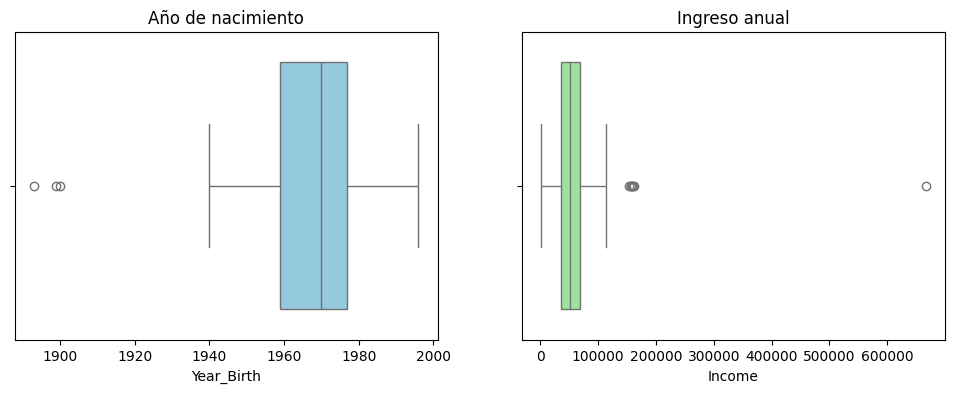

,ID,Year_Birth,Income
192,7829,1900,36640.0
239,11004,1893,60182.0
339,1150,1899,83532.0
2233,9432,1977,666666.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))                     # Una figura con 2 gráficas lado a lado
sns.boxplot(x=df['Year_Birth'], ax=axes[0], color='skyblue')        # Caja del año de nacimiento
axes[0].set_title('Año de nacimiento')                               # Título de la primera gráfica
sns.boxplot(x=df['Income'], ax=axes[1], color='lightgreen')         # Caja del ingreso
axes[1].set_title('Ingreso anual')                                   # Título de la segunda gráfica
plt.show()                                                           # Muestra las gráficas

df[(df['Year_Birth'] <= 1900) | (df['Income'] > 200000)][['ID', 'Year_Birth', 'Income']]  # Muestra los clientes sospechosos

¿Qué observamos?

Faltantes: solo Income tiene 24 faltantes (1.1 % de los clientes).
Duplicados: no hay filas idénticas, pero sin contar el ID aparecen 182 clientes repetidos (8 %). Es el mismo cliente registrado dos veces con distinto código.
Categóricas: Marital_Status tiene valores sin sentido: Absurd (2) y YOLO (2), que son errores de captura, y Alone (3), que significa lo mismo que Single. En Education, 2n Cycle equivale a una maestría.
Atípicos: 3 clientes nacieron en 1900 o antes (más de 120 años), lo cual es imposible, y un cliente declara un ingreso de 666 666, muy lejos del resto. Los ingresos de entre 150 000 y 160 000 son altos pero creíbles.


# 4. PREPARACIÓN DE LOS DATOS

*Limpieza, variables derivadas (por ejemplo, RFM), codificación de categóricas (`pd.get_dummies`), estandarización (`StandardScaler`) y división entrenamiento/prueba (`train_test_split` con `test_size=0.30` y `random_state=SEMILLA`). Guarden los datos preparados en `data/processed/`.*

4.1 Limpieza
En esta fase vamos a aplicar las decisiones de la sección 3.3:

Eliminar las columnas constantes.
Eliminar los faltantes y los clientes duplicados.
Corregir los estados civiles.
Eliminar las edades imposibles y el ingreso extremo.

In [9]:
df_limpio = df.copy()                                                          # Copia para no modificar los datos originales
df_limpio['Marital_Status'] = df_limpio['Marital_Status'].replace('Alone', 'Single')  # Alone significa lo mismo que Single
df_limpio = df_limpio.drop(['Z_CostContact', 'Z_Revenue'], axis=1) \
                     .dropna()                                                 # Quita las 2 columnas constantes y los 24 sin ingreso
df_limpio = df_limpio.drop_duplicates(subset=df_limpio.columns.drop('ID'))     # Quita clientes repetidos ignorando el ID
df_limpio = df_limpio[~df_limpio['Marital_Status'].isin(['Absurd', 'YOLO'])]   # Quita estados civiles sin sentido
df_limpio = df_limpio[(df_limpio['Year_Birth'] > 1900) & (df_limpio['Income'] < 600000)]  # Quita edades imposibles e ingreso extremo
df_limpio = df_limpio.reset_index(drop=True)                                   # Renumera las filas desde 0

print("Antes de limpiar :", df.shape)                                          # Tamaño original
print("Después de limpiar:", df_limpio.shape)                                  # Tamaño final
print(df_limpio['Marital_Status'].value_counts())                              # Comprueba que ya no hay valores raros

Antes de limpiar : (2240, 29)
Después de limpiar: (2025, 27)
Marital_Status
Married     788
Together    512
Single      440
Divorced    215
Widow        70
Name: count, dtype: int64


¿Qué observamos? Pasamos de 2240 a 2025 clientes: eliminamos 215 filas (9.6 %), casi todas duplicadas. Seguimos muy por encima del mínimo de 400 casos.

# variables derivadas (4.2)

4.2 Variables derivadas
En esta fase vamos a crear 7 variables nuevas que resumen mejor a cada cliente y que son más fáciles de explicar a la gerencia.

In [10]:
df_limpio['Dt_Customer'] = pd.to_datetime(df_limpio['Dt_Customer'], format='%d-%m-%Y')  # Convierte el texto a fecha real
fecha_ref = df_limpio['Dt_Customer'].max()                                    # Fecha más reciente del conjunto (referencia)

productos = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
canales   = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
campanas  = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']

df_limpio['Edad']          = fecha_ref.year - df_limpio['Year_Birth']                 # Edad del cliente en el año de referencia
df_limpio['Hijos']         = df_limpio['Kidhome'] + df_limpio['Teenhome']             # Total de hijos en casa
df_limpio['En_Pareja']     = df_limpio['Marital_Status'].isin(['Married', 'Together']).astype(int)  # 1 si vive en pareja
df_limpio['Gasto_Total']   = df_limpio[productos].sum(axis=1)                         # Monetario (M): gasto total en 2 años
df_limpio['Compras_Total'] = df_limpio[canales].sum(axis=1)                           # Frecuencia (F): número total de compras
df_limpio['Antiguedad']    = (fecha_ref - df_limpio['Dt_Customer']).dt.days           # Días que lleva como cliente
df_limpio['Campanas_Acep'] = df_limpio[campanas].sum(axis=1)                          # Cuántas campañas anteriores aceptó

df_limpio[['Edad', 'Hijos', 'En_Pareja', 'Gasto_Total', 'Compras_Total', 'Antiguedad', 'Campanas_Acep']].describe().T  # Revisa las nuevas variables

,count,mean,std,min,25%,50%,75%,max
Edad,2025.0,45.115062,11.656145,18.0,37.0,44.0,55.0,74.0
Hijos,2025.0,0.952593,0.746351,0.0,0.0,1.0,1.0,3.0
En_Pareja,2025.0,0.641975,0.479538,0.0,0.0,1.0,1.0,1.0
Gasto_Total,2025.0,607.708642,603.458917,5.0,69.0,397.0,1048.0,2525.0
Compras_Total,2025.0,12.559012,7.192689,0.0,6.0,12.0,18.0,32.0
Antiguedad,2025.0,352.470123,202.443561,0.0,178.0,352.0,528.0,699.0
Campanas_Acep,2025.0,0.300741,0.679255,0.0,0.0,0.0,0.0,4.0


¿Qué observamos?

Las edades van de 18 a 74 años (promedio de 45): ya no hay edades imposibles.
En Gasto_Total la mediana es 397 y la media 608: pocos clientes gastan mucho. Eso anticipa que habrá un grupo de “clientes de alto valor”.
La antigüedad va de 0 a 699 días: todos se registraron en un periodo de unos 2 años.
La mayoría no aceptó ninguna campaña anterior (la mediana de Campanas_Acep es 0).

# gráficos de exploración (4.3)

Celda A, la variable de clase:

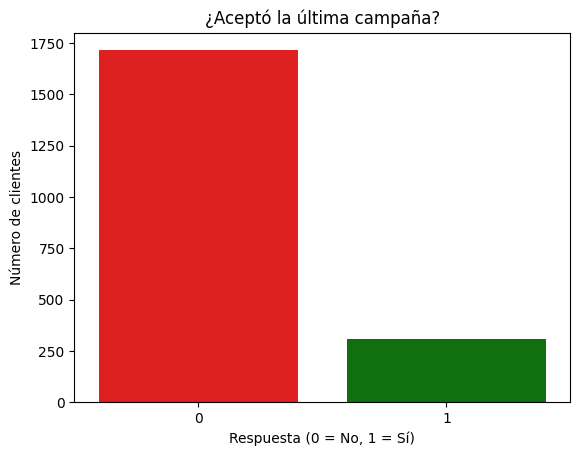

Response
0    0.846914
1    0.153086
Name: proportion, dtype: float64


In [11]:
sns.countplot(x='Response', data=df_limpio, hue='Response', palette=['red', 'green'], legend=False)  # Cuántos aceptaron (1) y no (0)
plt.title('¿Aceptó la última campaña?')                         # Título
plt.xlabel('Respuesta (0 = No, 1 = Sí)')                        # Eje X
plt.ylabel('Número de clientes')                                # Eje Y
plt.show()
print(df_limpio['Response'].value_counts(normalize=True))      # Proporción de cada clase

¿Qué observamos? El 84.7 % de los clientes no aceptó la última campaña y solo el 15.3 % sí. Las clases están desbalanceadas: en el Área 1 no basta con la exactitud, hay que revisar cuántos aceptantes detecta el modelo

Celda B, histogramas:

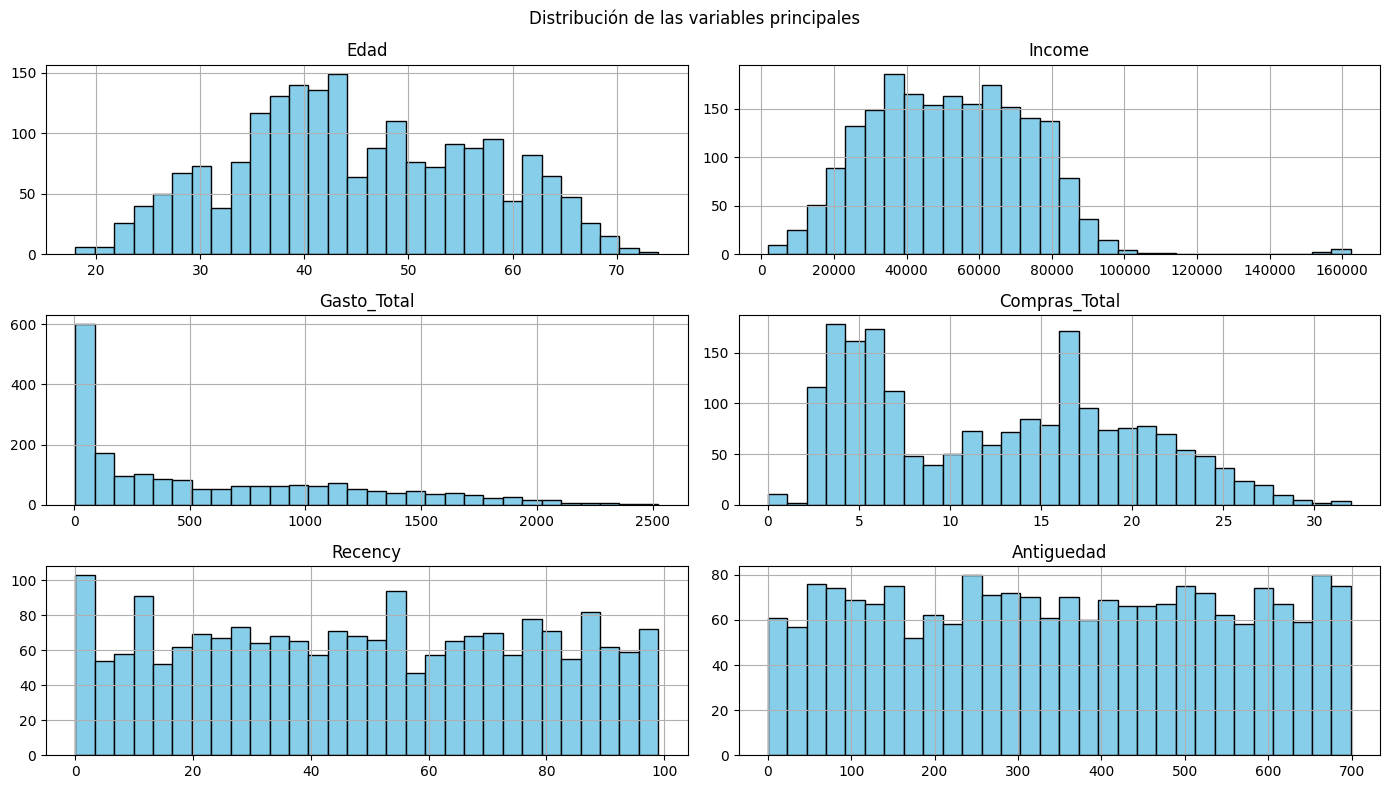

In [12]:
df_limpio[['Edad', 'Income', 'Gasto_Total', 'Compras_Total', 'Recency', 'Antiguedad']] \
    .hist(bins=30, figsize=(14, 8), color='skyblue', edgecolor='black')  # Un histograma por variable
plt.suptitle('Distribución de las variables principales')                # Título general
plt.tight_layout()                                                       # Acomoda para que no se encimen
plt.show()

¿Qué observamos?

Edad e Income tienen forma de campana; la mayoría gana entre 20 000 y 90 000.
Gasto_Total está muy cargado a la izquierda: muchos clientes gastan casi nada y pocos gastan mucho.
Compras_Total tiene dos picos (cerca de 5 y cerca de 15-20). Esto sugiere que hay dos tipos de compradores, ocasionales y frecuentes, y es una pista para el agrupamiento.
Recency y Antiguedad son casi uniformes: hay clientes de todos los niveles.

Celda C, PairGrid (como en la lección 2.2):

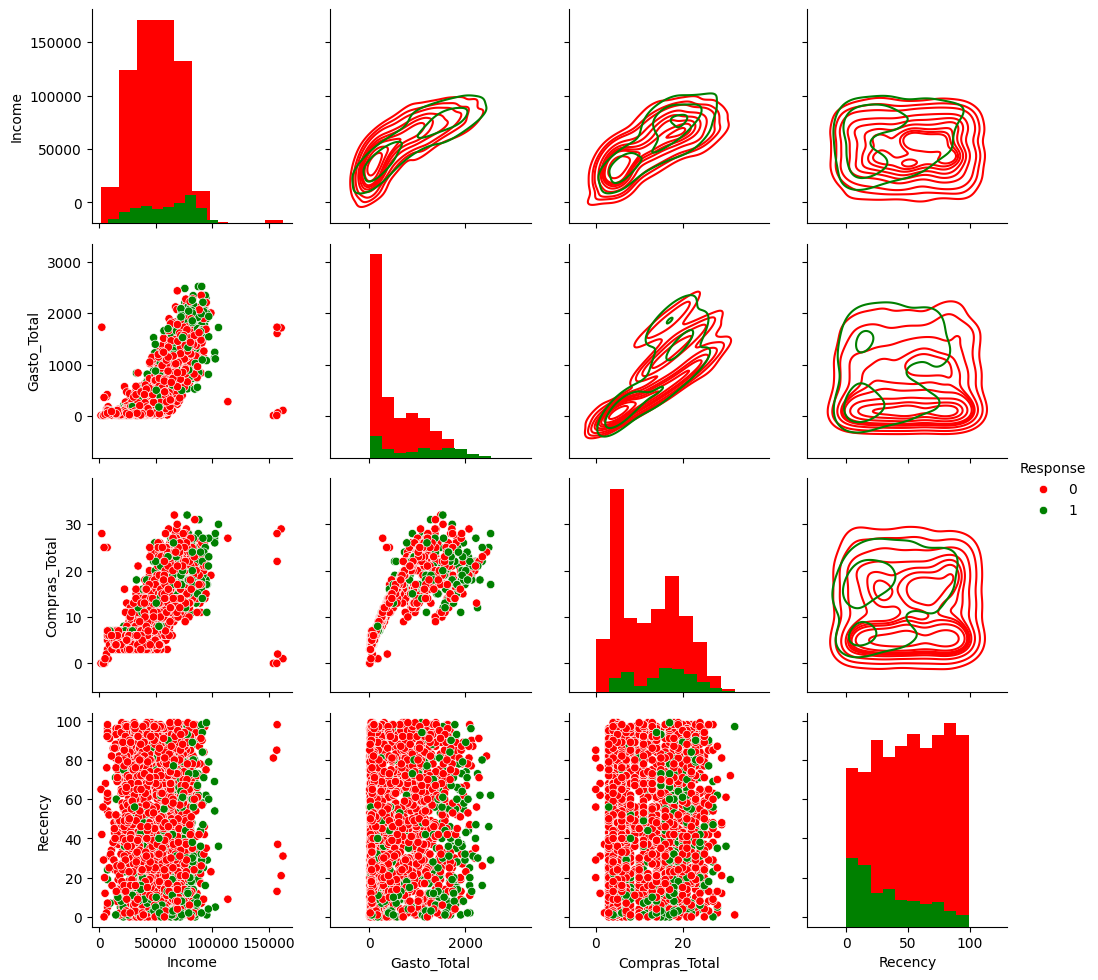

In [13]:
g = sns.PairGrid(df_limpio, vars=['Income', 'Gasto_Total', 'Compras_Total', 'Recency'],
                 hue='Response', diag_sharey=False, palette=['red', 'green'])  # Cruza 4 variables, coloreadas por la clase
g.map_diag(plt.hist)          # Diagonal: histograma de cada variable
g.map_upper(sns.kdeplot)      # Arriba: curvas de densidad
g.map_lower(sns.scatterplot)  # Abajo: dispersión punto por punto
g.add_legend()                # Leyenda
plt.show()

¿Qué observamos?

A mayor ingreso, mayor gasto y más compras: hay una relación positiva fuerte.
Los que aceptaron (verde) se concentran en Recency baja. Los clientes que compraron hace poco responden más a las campañas, así que será una variable clave del Área 1.
Los verdes también aparecen más en gasto alto.
Hay unos pocos clientes con ingreso cercano a 150 000 pero gasto casi nulo: un perfil atípico que vale la pena mencionar.

# guardar los datos limpios (4.4)

In [14]:
os.makedirs('data/processed', exist_ok=True)                                  # Crea la carpeta si no existe
df_limpio.to_csv('data/processed/clientes_limpio.csv', sep=',', index=False)  # Guarda los datos limpios sin el índice
print("Datos guardados:", df_limpio.shape)                                    # Confirma el tamaño guardado

Datos guardados: (2025, 34)


# 5.1 ÁREA 1: CAMPAÑAS DE MARKETING (A1)

**Pregunta de negocio:** ¿A qué clientes debe dirigir el equipo de marketing la próxima campaña para conseguir la mayor cantidad de aceptaciones contactando a menos personas?

- **Decisión que apoya:** a quién incluir en la lista de contacto de la campaña.
- **Quién decide:** el gerente de marketing.
- **Criterio de éxito:** que el modelo detecte al menos el 60 % de los clientes que sí aceptarán (en los datos de prueba), y que entre los clientes que recomienda contactar acepte más del 15 % actual.

**Tipo de problema:** supervisado (clasificación). La variable de clase `y` es `Response` (1 = aceptó la campaña, 0 = no aceptó).

## 5.1.1 Reducción de dimensionalidad (si aplica)

*PCA: varianza explicada, número de componentes y gráfico 2D (lecciones 1.3 y 1.6-1.7). LDA o t-SNE para comparar (lecciones 1.4 y 1.5).*

**Preparación del Área 1**

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV    # Dividir los datos y buscar los mejores parámetros
from sklearn.preprocessing import StandardScaler                      # Estandarizar las variables
from sklearn.decomposition import PCA                                 # Reducción con componentes principales
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis  # Reducción supervisada (LDA)
from sklearn.neighbors import KNeighborsClassifier                    # Clasificador kNN
from sklearn.naive_bayes import GaussianNB                            # Clasificador Naive Bayes
from sklearn.tree import DecisionTreeClassifier, plot_tree            # Árbol de decisión y su dibujo

In [16]:
# Celda 1, variables y codificación:

variables = ['Income', 'Edad', 'Hijos', 'En_Pareja', 'Recency', 'Antiguedad', 'Complain',
             'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
             'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
             'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']        # Atributos que usará el modelo

X = pd.get_dummies(df_limpio[variables + ['Education']], columns=['Education'],
                   drop_first=True, dtype=int)            # Convierte Education en columnas de 0 y 1
y = df_limpio['Response']                                 # Variable de clase: 1 = aceptó la campaña
print("Atributos (X):", X.shape)                          # Debe dar 27 columnas
X.head()

Atributos (X): (2025, 27)


,Income,Edad,Hijos,En_Pareja,Recency,Antiguedad,Complain,MntWines,MntFruits,MntMeatProducts,...,NumWebVisitsMonth,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Education_Basic,Education_Graduation,Education_Master,Education_PhD
0,58138.0,57,0,0,58,663,0,635,88,546,...,7,0,0,0,0,0,0,1,0,0
1,46344.0,60,2,0,38,113,0,11,1,6,...,5,0,0,0,0,0,0,1,0,0
2,71613.0,49,0,1,26,312,0,426,49,127,...,4,0,0,0,0,0,0,1,0,0
3,26646.0,30,1,1,26,139,0,11,4,20,...,6,0,0,0,0,0,0,1,0,0
4,58293.0,33,1,1,94,161,0,173,43,118,...,5,0,0,0,0,0,0,0,0,1


In [17]:
# Celda 2, división 70/30 y estandarización:

X_trn, X_tst, y_trn, y_tst = train_test_split(X, y, test_size=0.30,
                                              random_state=SEMILLA, stratify=y)  # 70 % entrenamiento, 30 % prueba
print("Entrenamiento:", X_trn.shape, " Prueba:", X_tst.shape)                    # Tamaños de cada parte
print("Aceptan en entrenamiento: {:.2%}".format(y_trn.mean()))                   # Debe salir cerca del 15 %
print("Aceptan en prueba:        {:.2%}".format(y_tst.mean()))                   # También cerca del 15 %

scaler = StandardScaler()                      # Crea el estandarizador
X_trn_s = scaler.fit_transform(X_trn)          # Aprende media y desviación SOLO con entrenamiento y transforma
X_tst_s = scaler.transform(X_tst)              # Aplica esa misma transformación a prueba

Entrenamiento: (1417, 27)  Prueba: (608, 27)
Aceptan en entrenamiento: 15.31%
Aceptan en prueba:        15.30%


## 5.1.1 Reducción de dimensionalidad: PCA vs LDA

Componentes para explicar el 90 %: 19


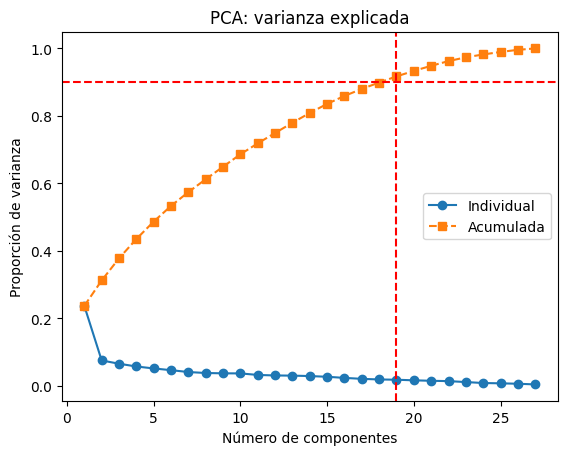

In [18]:
# Celda 1, PCA: ¿cuántos componentes?

pca = PCA()                                                  # PCA con todos los componentes
trn_tf = pca.fit_transform(X_trn_s)                          # Ajusta y transforma solo entrenamiento
var_acum = pca.explained_variance_ratio_.cumsum()            # Varianza explicada acumulada
n90 = np.argmax(var_acum >= 0.90) + 1                        # Primer número de componentes que llega al 90 %
print("Componentes para explicar el 90 %:", n90)

x = range(1, len(var_acum) + 1)                              # Números de componente: 1, 2, 3...
plt.plot(x, pca.explained_variance_ratio_, 'o-', label='Individual')  # Varianza de cada componente
plt.plot(x, var_acum, 's--', label='Acumulada')              # Varianza acumulada
plt.axhline(0.90, color='red', ls='--')                      # Línea del 90 %
plt.axvline(n90, color='red', ls='--')                       # Componentes necesarios
plt.title('PCA: varianza explicada')
plt.xlabel('Número de componentes')
plt.ylabel('Proporción de varianza')
plt.legend()
plt.show()

Varianza explicada por PC1 + PC2: 31.23%


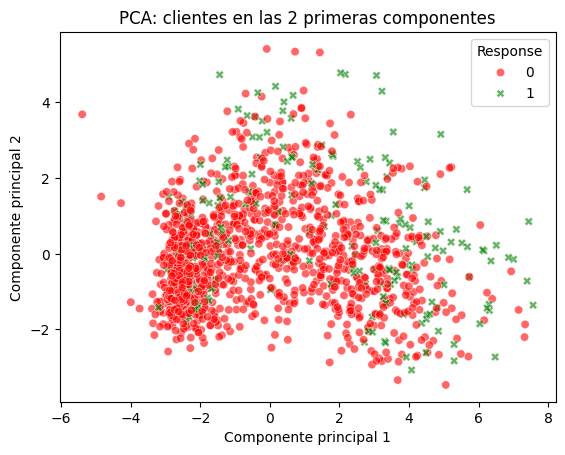

In [19]:
# Celda 2, PCA en 2D:

print("Varianza explicada por PC1 + PC2: {:.2%}".format(var_acum[1]))      # Cuánto resumen las 2 primeras
sns.scatterplot(x=trn_tf[:, 0], y=trn_tf[:, 1], hue=y_trn, style=y_trn,
                palette=['red', 'green'], alpha=0.6)                       # Cada punto es un cliente
plt.title('PCA: clientes en las 2 primeras componentes')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.show()

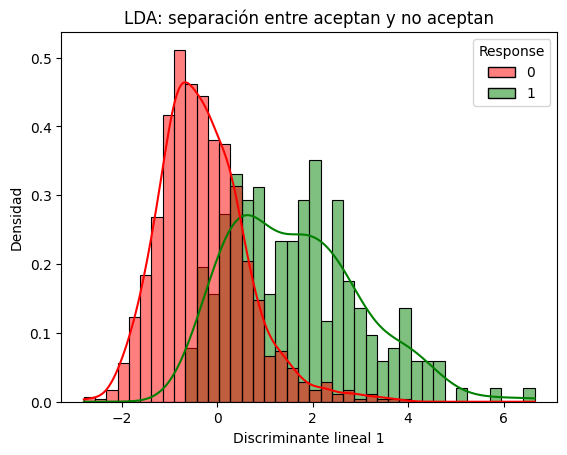

Exactitud de LDA en prueba = 89.14%


In [20]:
# Celda 3, LDA para comparar:

lda = LinearDiscriminantAnalysis()                           # Crea el modelo LDA
lda.fit(X_trn_s, y_trn)                                      # Aprende usando la clase (supervisado)
trn_lda = lda.transform(X_trn_s)                             # Proyecta los clientes en el eje discriminante

sns.histplot(x=trn_lda[:, 0], hue=y_trn, palette=['red', 'green'],
             kde=True, stat='density', common_norm=False)    # Distribución de cada clase sobre el eje LDA
plt.title('LDA: separación entre aceptan y no aceptan')
plt.xlabel('Discriminante lineal 1')
plt.ylabel('Densidad')
plt.show()
print('Exactitud de LDA en prueba = {:.2%}'.format(lda.score(X_tst_s, y_tst)))  # Evaluado en PRUEBA

¿Qué observamos? (PCA vs LDA)

PCA necesita 19 de 27 componentes para explicar el 90 % de la varianza. La información está muy repartida, así que no se puede resumir en pocas variables. Las 2 primeras componentes explican solo el 31.23 %.
En el gráfico 2D de PCA, los que aceptan (verde) tienden a la derecha de la componente 1, donde están los clientes de mayor gasto, pero siguen muy mezclados con los rojos. PCA no usa la clase, solo busca variación.
LDA, que sí usa la clase, encuentra un solo eje donde los dos grupos se separan bastante mejor: los rojos se concentran a la izquierda y los verdes a la derecha, aunque con una zona de traslape.
LDA logra 89.14 % de exactitud en prueba, frente al 84.7 % que se obtendría diciendo siempre “no”. Conclusión: para este problema supervisado, LDA es más útil que PCA.

## 5.1.2 Modelado

*Si es **agrupamiento**: elección de K con la silueta (lección 2.4), segundo método (jerárquico, lección 2.3, o DBSCAN, lección 2.5) y perfil de cada grupo en unidades originales con `groupby(...).mean()`.*

*Si es **clasificación**: kNN y árbol optimizados con `GridSearchCV`, Naive Bayes, y para cada modelo la matriz de confusión y la exactitud en los datos de **prueba** (lecciones 3.3 a 3.5).*

In [21]:
# Celda 1, función para evaluar (así no repetimos código):
def evaluar(modelo, nombre, X_eval):
    y_pred = modelo.predict(X_eval)                          # Predice sobre los datos de PRUEBA
    exac = (y_pred == y_tst).mean()                          # Exactitud: % de aciertos totales
    sens = y_pred[(y_tst == 1).values].mean()                # Sensibilidad: % de aceptantes que detecta
    prec = y_tst[y_pred == 1].mean()                         # Precisión: % de contactados que sí aceptan
    print(nombre)
    print('  Exactitud en prueba    = {:.2%}'.format(exac))
    print('  Sensibilidad (detecta) = {:.2%}'.format(sens))
    print('  Precisión (contactos)  = {:.2%}'.format(prec))
    display(pd.crosstab(y_tst, y_pred, rownames=['Clase real'], colnames=['Clase predicha']))  # Matriz de confusión
    return exac, sens, prec

In [22]:
# Celda 2, kNN optimizado:
param_knn = {'n_neighbors': range(1, 31, 2), 'weights': ['uniform', 'distance']}   # Valores a probar
grid_knn = GridSearchCV(KNeighborsClassifier(), param_knn, scoring='f1', cv=5)     # Busca la mejor combinación
grid_knn.fit(X_trn_s, y_trn)                                                        # Entrena solo con entrenamiento
best_knn = grid_knn.best_estimator_                                                 # Mejor modelo encontrado
print('Mejores parámetros kNN:', grid_knn.best_params_)
res_knn = evaluar(best_knn, 'kNN', X_tst_s)                                         # Evalúa en prueba

Mejores parámetros kNN: {'n_neighbors': 3, 'weights': 'uniform'}
kNN
  Exactitud en prueba    = 85.03%
  Sensibilidad (detecta) = 32.26%
  Precisión (contactos)  = 51.72%


Clase predicha,0,1
Clase real,,
0,487,28
1,63,30


In [23]:
# Celda 3, Naive Bayes:
nb = GaussianNB()                                  # Naive Bayes no tiene parámetros que optimizar
nb.fit(X_trn_s, y_trn)                             # Entrena
res_nb = evaluar(nb, 'Naive Bayes', X_tst_s)       # Evalúa en prueba

Naive Bayes
  Exactitud en prueba    = 82.57%
  Sensibilidad (detecta) = 59.14%
  Precisión (contactos)  = 44.72%


Clase predicha,0,1
Clase real,,
0,447,68
1,38,55


In [24]:
# Celda 4, árbol optimizado:

param_arbol = {'max_depth': range(2, 11), 'min_samples_leaf': [1, 5, 10, 20],
               'class_weight': [None, 'balanced']}                                  # Valores a probar
grid_arbol = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), param_arbol,
                          scoring='f1', cv=5)                                       # Busca la mejor combinación
grid_arbol.fit(X_trn, y_trn)                                                        # Sin estandarizar (no hace falta)
best_arbol = grid_arbol.best_estimator_
print('Mejores parámetros árbol:', grid_arbol.best_params_)
res_arbol = evaluar(best_arbol, 'Árbol de decisión', X_tst)                         # Evalúa en prueba

Mejores parámetros árbol: {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 20}
Árbol de decisión
  Exactitud en prueba    = 75.33%
  Sensibilidad (detecta) = 68.82%
  Precisión (contactos)  = 34.59%


Clase predicha,0,1
Clase real,,
0,394,121
1,29,64


In [25]:
#  Celda 1, verificar esos valores:
print("Costo por contacto:", df['Z_CostContact'].unique())   # Valor constante del dataset original
print("Ingreso por aceptación:", df['Z_Revenue'].unique())    # Valor constante del dataset original

Costo por contacto: [3]
Ingreso por aceptación: [11]


In [26]:
# Celda 2, tabla comparativa:
COSTO, INGRESO = 3, 11                                           # Supuestos tomados del dataset
filas = []
for nombre, modelo, X_eval in [('kNN', best_knn, X_tst_s), ('Naive Bayes', nb, X_tst_s), ('Árbol', best_arbol, X_tst)]:
    y_pred = modelo.predict(X_eval)                              # Predicción en PRUEBA
    vp = ((y_pred == 1) & (y_tst == 1)).sum()                    # Verdaderos positivos: contactados que aceptan
    fp = ((y_pred == 1) & (y_tst == 0)).sum()                    # Falsos positivos: contactados que NO aceptan
    fn = ((y_pred == 0) & (y_tst == 1)).sum()                    # Falsos negativos: aceptantes que NO contactamos
    filas.append([nombre, (y_pred == y_tst).mean(), vp / (vp + fn), vp / (vp + fp),
                  vp + fp, vp, fn, INGRESO * vp - COSTO * (vp + fp)])
total = len(y_tst); acept = y_tst.sum()                          # Escenario actual: llamar a todos
filas.append(['Contactar a todos', acept / total, 1.0, acept / total, total, acept, 0, INGRESO * acept - COSTO * total])

comparacion = pd.DataFrame(filas, columns=['Modelo', 'Exactitud', 'Sensibilidad', 'Precisión',
                                           'Contactos', 'Aceptan', 'Perdidos', 'Ganancia'])
comparacion

,Modelo,Exactitud,Sensibilidad,Precisión,Contactos,Aceptan,Perdidos,Ganancia
0,kNN,0.850329,0.322581,0.517241,58,30,63,156
1,Naive Bayes,0.825658,0.591398,0.447154,123,55,38,236
2,Árbol,0.753289,0.688172,0.345946,185,64,29,149
3,Contactar a todos,0.152961,1.000000,0.152961,608,93,0,-801


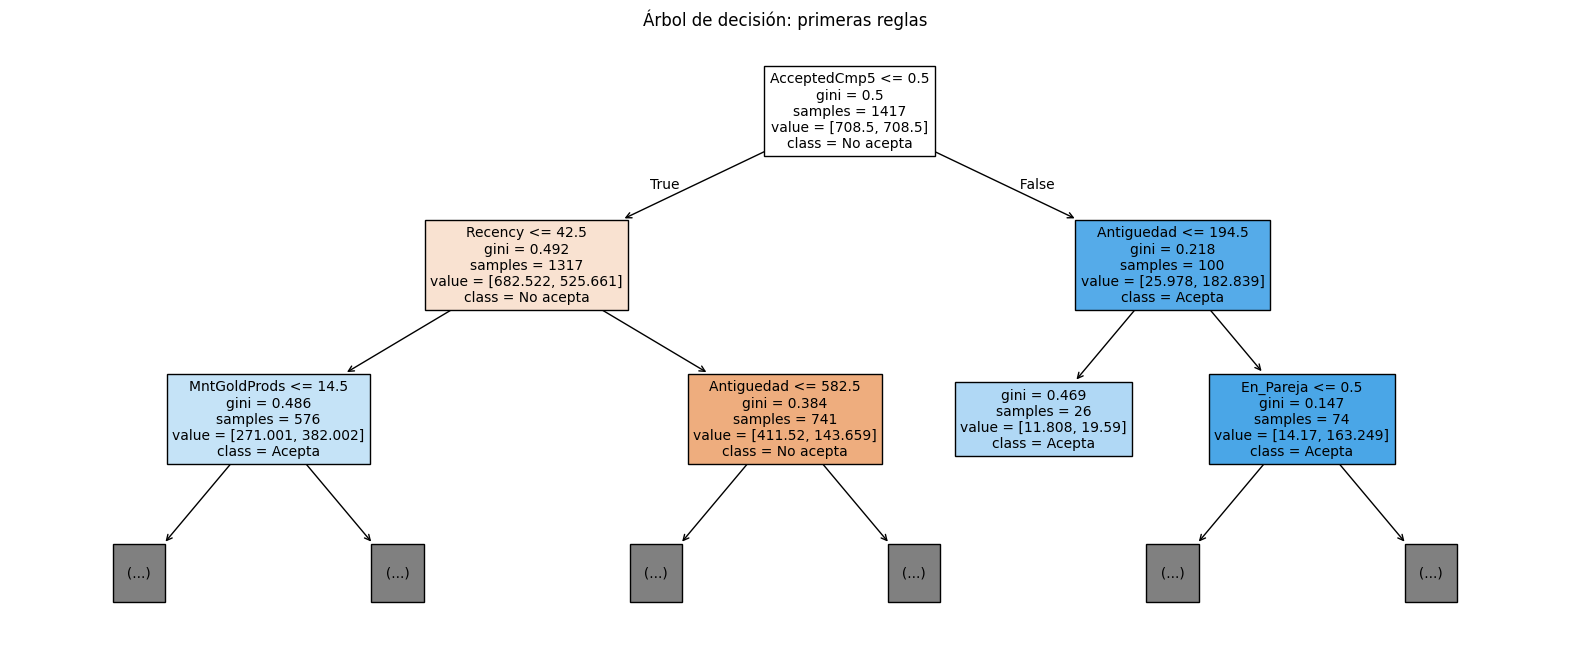

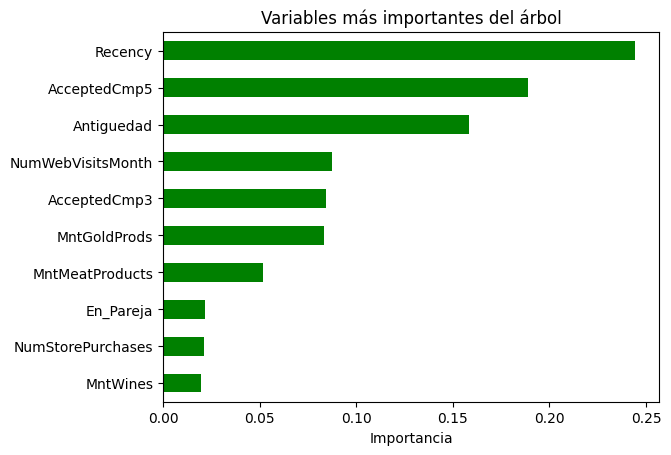

In [27]:
# Celda 3, las reglas del árbol (para explicárselas al gerente):

plt.figure(figsize=(20, 8))                                                  # Figura grande para que se lea
plot_tree(best_arbol, max_depth=2, feature_names=X.columns,
          class_names=['No acepta', 'Acepta'], filled=True, fontsize=10)    # Solo los 2 primeros niveles
plt.title('Árbol de decisión: primeras reglas')
plt.show()

importancia = pd.Series(best_arbol.feature_importances_, index=X.columns).sort_values(ascending=False)  # Peso de cada variable
importancia.head(10).plot(kind='barh', color='green')                       # Las 10 más importantes
plt.title('Variables más importantes del árbol')
plt.xlabel('Importancia')
plt.gca().invert_yaxis()                                                     # La más importante arriba
plt.show()

¿Qué observamos?

Los costos se toman del propio dataset: contactar a un cliente cuesta 3 y cada aceptación genera 11.
Contactar a todos (la estrategia actual) da una pérdida de 801: se hacen 608 llamadas para conseguir 93 aceptaciones.
kNN tiene la mayor exactitud (85 %), pero solo detecta el 32 % de los aceptantes: deja escapar a 63 de 93. La exactitud engaña cuando las clases están desbalanceadas.
Naive Bayes logra la mayor ganancia (236): con 123 llamadas consigue 55 aceptaciones.
El árbol es el que más aceptantes detecta (68.8 %, 64 de 93) con solo 185 llamadas, y es el único que cumple el criterio de éxito (≥ 60 % detectados y precisión > 15 %).
Según el árbol, las variables que más influyen son Recency (días desde la última compra), AcceptedCmp5 (si aceptó la campaña 5) y Antiguedad. La primera regla es: si el cliente aceptó la campaña 5, muy probablemente acepte la siguiente.

## 5.1.3 Interpretación para el negocio

*¿Qué responde este resultado a la pregunta de negocio? ¿Qué decisión recomiendan? ¿Qué error es más costoso?*

Respuesta a la pregunta: el equipo de marketing debe dirigir la campaña a los clientes que el árbol de decisión clasifica como “Acepta”. Con ese criterio, llamando solo al 30 % de la base (185 de 608) se captan el 69 % de las aceptaciones, y la tasa de aceptación sube del 15 % al 35 %, más del doble.

¿Qué error es más costoso? El falso negativo: no llamar a un cliente que sí habría aceptado cuesta 11 en venta perdida. Un falso positivo (una llamada inútil) cuesta solo 3. Por eso elegimos el modelo que menos aceptantes pierde, aunque su exactitud sea menor.

Recomendaciones:

Priorizar a los clientes que compraron hace poco (Recency menor a ~42 días) y a los que aceptaron campañas anteriores, sobre todo la 5.
Si el presupuesto es muy limitado, usar Naive Bayes: hace menos llamadas (123) y da la mayor ganancia (236).

Despliegue: antes de cada campaña se pasa la base de clientes por el modelo y se entrega al call center la lista de los clasificados como “Acepta”.

Monitoreo: comparar en cada campaña la tasa de aceptación de los contactados con la del 15 % histórico, y reentrenar el modelo cada 6 meses o cuando la tasa baje del 25 %.

Limitaciones: los costos (3 y 11) son los del dataset y no fueron verificados con la empresa; además, las clases están desbalanceadas (15 %).

# 5.2 ÁREA 2: SEGMENTACIÓN DE MERCADO (A2)

**Pregunta de negocio:** ¿Qué grupos de clientes existen según su perfil (ingreso, edad, hijos) y lo que compran (vinos, carnes, frutas, etc.), y qué estrategia comercial merece cada grupo?

- **Decisión que apoya:** qué productos, promociones y mensajes ofrecer a cada segmento.
- **Quién decide:** el gerente comercial.
- **Criterio de éxito:** encontrar entre 3 y 6 grupos con silueta mayor a 0.25, cada uno con un perfil claramente distinto en ingreso y gasto, al que se le pueda poner un nombre comercial.

**Tipo de problema:** no supervisado (agrupamiento). No hay variable de clase.

## 5.2.1 Reducción de dimensionalidad (si aplica)

*PCA: varianza explicada, número de componentes y gráfico 2D (lecciones 1.3 y 1.6-1.7). LDA o t-SNE para comparar (lecciones 1.4 y 1.5).*

# Celda de código, variables y estandarización:

In [28]:
vars_seg = ['Income', 'Edad', 'Hijos', 'MntWines', 'MntFruits', 'MntMeatProducts',
            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']     # Perfil del cliente + qué compra
seg = df_limpio[vars_seg]                                             # Datos en unidades originales (para perfilar)
seg_s = StandardScaler().fit_transform(seg)                           # Datos estandarizados (para k-means)
print("Clientes y variables:", seg_s.shape)

Clientes y variables: (2025, 9)


# ## 5.2.1 Reducción de dimensionalidad

Varianza explicada por PC1 + PC2: 60.46%


,PC1,PC2
Income,0.39,0.26
Edad,0.05,0.83
Hijos,-0.29,0.33
MntWines,0.35,0.29
MntFruits,0.36,-0.14
MntMeatProducts,0.40,-0.03
MntFishProducts,0.37,-0.13
MntSweetProducts,0.36,-0.13
MntGoldProds,0.28,0.03


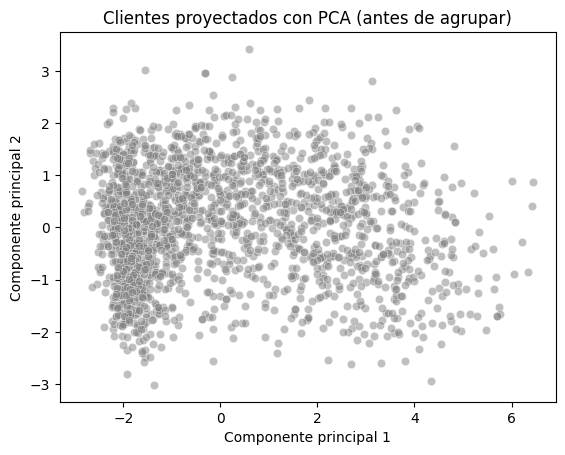

In [29]:
pca_seg = PCA(n_components=2)                                         # Reducimos a 2 dimensiones para poder graficar
seg_pca = pca_seg.fit_transform(seg_s)                                # Coordenadas de cada cliente en PC1 y PC2
print("Varianza explicada por PC1 + PC2: {:.2%}".format(pca_seg.explained_variance_ratio_.sum()))

cargas = pd.DataFrame(pca_seg.components_.T, index=vars_seg, columns=['PC1', 'PC2'])  # Peso de cada variable
display(cargas.round(2))

sns.scatterplot(x=seg_pca[:, 0], y=seg_pca[:, 1], alpha=0.5, color='gray')  # Clientes sin agrupar todavía
plt.title('Clientes proyectados con PCA (antes de agrupar)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.show()

¿Qué observamos?

Las 2 primeras componentes explican el 60.46 % de la varianza, suficiente para visualizar los grupos en 2D.
PC1 = “poder de compra”: Income y todos los gastos (Mnt...) pesan positivo (entre 0.28 y 0.40) y Hijos pesa negativo (−0.29). A la derecha están los que más ganan y gastan, y suelen tener menos hijos.
PC2 = “etapa de vida”: lo domina la Edad (0.83), seguida de Hijos (0.33) y vinos (0.29). Arriba están los clientes mayores.
La nube es muy densa a la izquierda (mucha gente que gasta poco) y se dispersa hacia la derecha (pocos clientes que gastan mucho).

## 5.2.2 Modelado

*Si es **agrupamiento**: elección de K con la silueta (lección 2.4), segundo método (jerárquico, lección 2.3, o DBSCAN, lección 2.5) y perfil de cada grupo en unidades originales con `groupby(...).mean()`.*

*Si es **clasificación**: kNN y árbol optimizados con `GridSearchCV`, Naive Bayes, y para cada modelo la matriz de confusión y la exactitud en los datos de **prueba** (lecciones 3.3 a 3.5).*

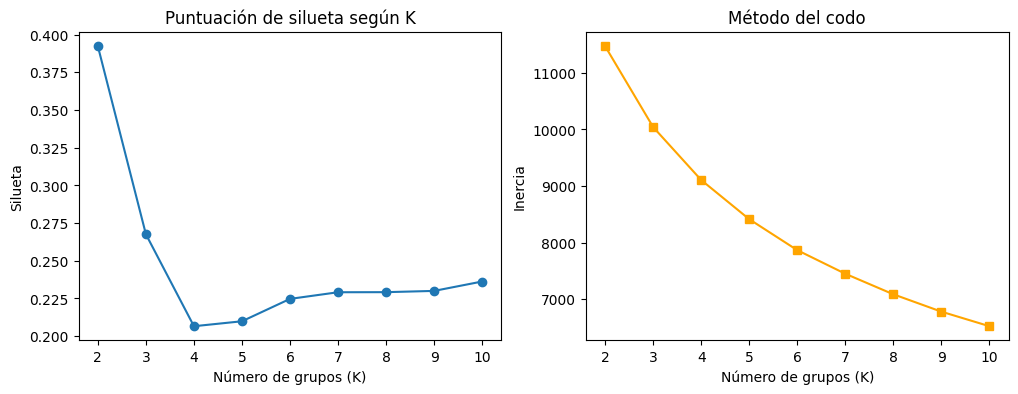

K = 2: silueta = 0.392
K = 3: silueta = 0.268
K = 4: silueta = 0.207
K = 5: silueta = 0.210
K = 6: silueta = 0.225
K = 7: silueta = 0.229
K = 8: silueta = 0.229
K = 9: silueta = 0.230
K = 10: silueta = 0.236


In [30]:
# k-means (5.2.2)

from sklearn.cluster import KMeans                     # Algoritmo k-means
from sklearn.metrics import silhouette_score           # Métrica de silueta

ks = range(2, 11)                                      # Valores de K a probar
siluetas, inercias = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo con K grupos
    etiquetas = km.fit_predict(seg_s)                  # Agrupa a los clientes
    siluetas.append(silhouette_score(seg_s, etiquetas))  # Qué tan bien separados quedan los grupos
    inercias.append(km.inertia_)                       # Qué tan compactos son los grupos

fig, axes = plt.subplots(1, 2, figsize=(12, 4))        # Dos gráficas lado a lado
axes[0].plot(ks, siluetas, 'o-')                       # Silueta para cada K
axes[0].set_title('Puntuación de silueta según K')
axes[0].set_xlabel('Número de grupos (K)')
axes[0].set_ylabel('Silueta')
axes[1].plot(ks, inercias, 's-', color='orange')       # Inercia para cada K (método del codo)
axes[1].set_title('Método del codo')
axes[1].set_xlabel('Número de grupos (K)')
axes[1].set_ylabel('Inercia')
plt.show()

for k, s in zip(ks, siluetas):
    print("K = {}: silueta = {:.3f}".format(k, s))     # Valores exactos para justificar la elección

¿Qué observamos? (elección de K)

La silueta más alta es K = 2 (0.392), pero dos grupos (“gastan mucho” y “gastan poco”) son demasiado generales para diseñar estrategias distintas.
K = 3 tiene la mejor silueta entre las opciones útiles para el negocio (0.268), supera el 0.25 del criterio de éxito y es claramente mejor que K = 4 a 10 (0.21 a 0.24).
En el método del codo la inercia baja fuerte de 2 a 4 y después se aplana, lo que también apoya un K pequeño.
Decisión: K = 3, justificado por la silueta y por el criterio de negocio (R4).

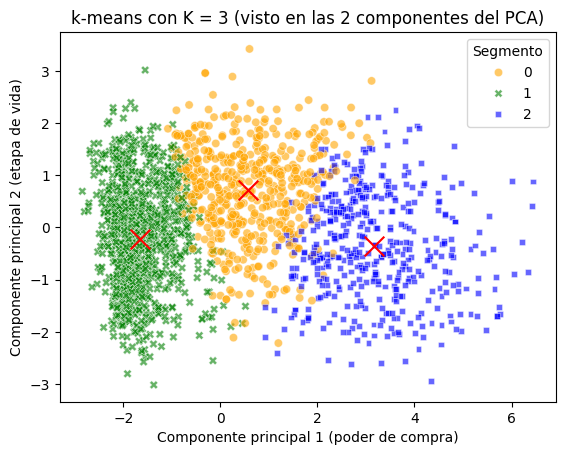

,Income,Edad,Hijos,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,Gasto_Total,Response,Clientes,% del total
Segmento,,,,,,,,,,,,,
0,63289.18,50.53,0.85,549.25,23.51,179.07,33.10,23.30,63.98,872.21,0.15,528,26.1
1,36088.15,42.57,1.29,66.88,5.36,30.76,7.48,5.43,17.20,133.10,0.10,1046,51.7
2,75849.36,44.68,0.28,573.45,77.86,472.66,111.55,82.21,81.08,1398.81,0.28,451,22.3


In [31]:
km = KMeans(n_clusters=3, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo final con K = 3
df_limpio['Segmento'] = km.fit_predict(seg_s)                  # Guarda el grupo de cada cliente
centros = pca_seg.transform(km.cluster_centers_)               # Lleva los centroides al plano del PCA

sns.scatterplot(x=seg_pca[:, 0], y=seg_pca[:, 1], hue=df_limpio['Segmento'], style=df_limpio['Segmento'],
                palette=['orange', 'green', 'blue'], alpha=0.6)            # Clientes coloreados por grupo
plt.scatter(centros[:, 0], centros[:, 1], marker='x', s=200, c='red')     # Centroides
plt.title('k-means con K = 3 (visto en las 2 componentes del PCA)')
plt.xlabel('Componente principal 1 (poder de compra)')
plt.ylabel('Componente principal 2 (etapa de vida)')
plt.show()

perfil = df_limpio.groupby('Segmento')[vars_seg + ['Gasto_Total', 'Response']].mean().round(2)  # Promedios en unidades ORIGINALES
perfil['Clientes'] = df_limpio['Segmento'].value_counts().sort_index()    # Tamaño de cada grupo
perfil['% del total'] = (perfil['Clientes'] / len(df_limpio) * 100).round(1)
perfil

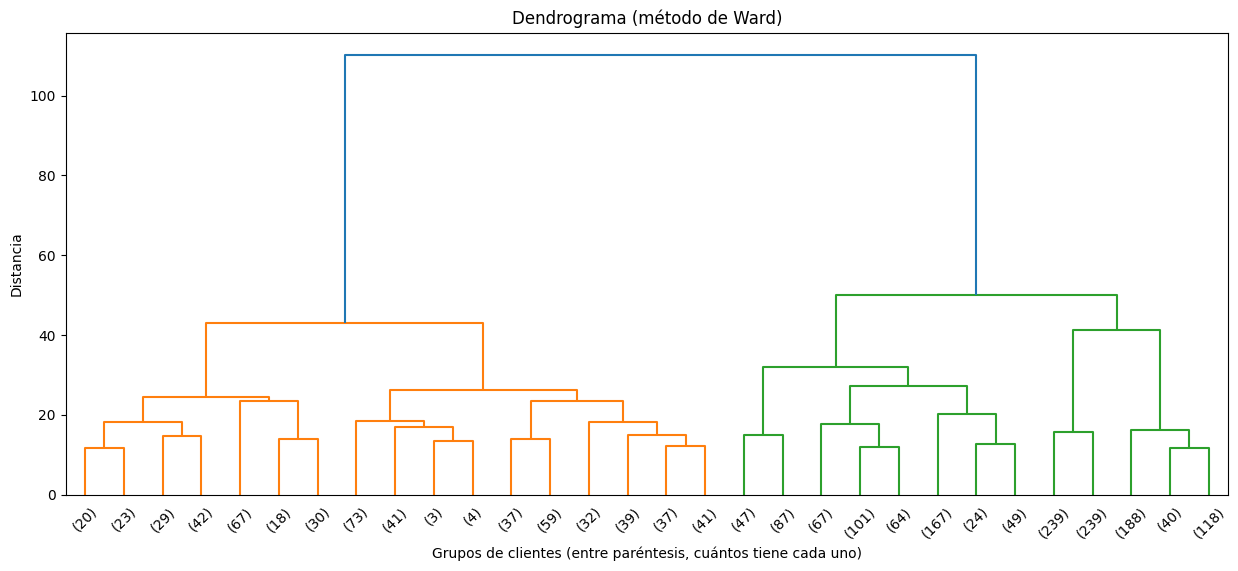

Silueta k-means    (K=3): 0.268
Silueta jerárquico (K=3): 0.178


Jerárquico,0,1,2
k-means,,,
0,172,344,12
1,1,233,812
2,422,29,0


In [32]:
# jerárquico (lo exige R4)

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster   # Agrupamiento jerárquico

hc = linkage(seg_s, method='ward', metric='euclidean')               # Une clientes paso a paso (método de Ward)
plt.figure(figsize=(15, 6))
dendrogram(hc, truncate_mode='lastp', p=30, leaf_font_size=10)       # Muestra solo las últimas 30 uniones para que se lea
plt.title('Dendrograma (método de Ward)')
plt.xlabel('Grupos de clientes (entre paréntesis, cuántos tiene cada uno)')
plt.ylabel('Distancia')
plt.show()

df_limpio['Jerarquico'] = fcluster(hc, t=3, criterion='maxclust') - 1   # Corta el árbol en 3 grupos (0, 1, 2)
print('Silueta k-means    (K=3): {:.3f}'.format(silhouette_score(seg_s, df_limpio['Segmento'])))
print('Silueta jerárquico (K=3): {:.3f}'.format(silhouette_score(seg_s, df_limpio['Jerarquico'])))
pd.crosstab(df_limpio['Segmento'], df_limpio['Jerarquico'],
            rownames=['k-means'], colnames=['Jerárquico'])            # ¿Coinciden los dos métodos?

¿Qué observamos? (k-means vs jerárquico)

En el dendrograma, el salto más grande (distancia ≈ 110) separa a los clientes en 2 grandes bloques. Eso coincide con la silueta, que también era máxima en K = 2. Al cortar más abajo (≈ 45-50) aparecen 3 grupos.
k-means separa mejor: silueta de 0.268 contra 0.178 del jerárquico.
Los dos métodos coinciden en el 78 % de los clientes (422 + 344 + 812 de 2025). Los grupos de los extremos son muy estables: el 94 % del grupo premium de k-means (422 de 451) también queda junto en el jerárquico, y el 78 % del grupo de bajo gasto (812 de 1046) también.
La diferencia está en el grupo intermedio (k-means 0): el jerárquico lo reparte entre sus vecinos.
Conclusión: nos quedamos con k-means, porque tiene mejor silueta y grupos más equilibrados. Que el jerárquico confirme los extremos demuestra que los segmentos son reales y no dependen del algoritmo.

Segmento,Adultos amantes del vino,Familias de presupuesto ajustado,Premium sin hijos
Income,63289.18,36088.15,75849.36
Edad,50.53,42.57,44.68
Hijos,0.85,1.29,0.28
MntWines,549.25,66.88,573.45
MntFruits,23.51,5.36,77.86
MntMeatProducts,179.07,30.76,472.66
MntFishProducts,33.10,7.48,111.55
MntSweetProducts,23.30,5.43,82.21
MntGoldProds,63.98,17.20,81.08
Gasto_Total,872.21,133.10,1398.81


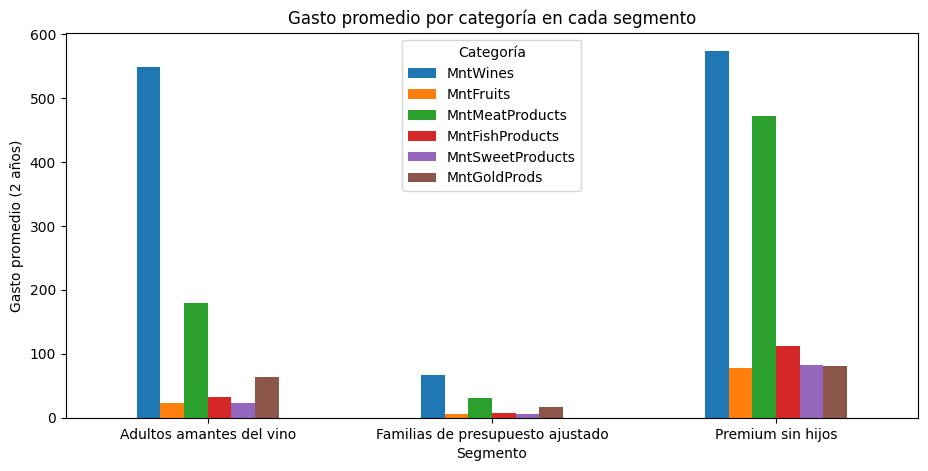

In [33]:
nombres = {0: 'Adultos amantes del vino', 1: 'Familias de presupuesto ajustado', 2: 'Premium sin hijos'}  # Nombre comercial de cada grupo
df_limpio['Nombre_Segmento'] = df_limpio['Segmento'].map(nombres)     # Agrega el nombre a cada cliente
perfil.index = perfil.index.map(nombres)                               # Pone los nombres en la tabla de perfiles
display(perfil.T)                                                      # Tabla completa (volteada para que se lea)

gasto_cat = df_limpio.groupby('Nombre_Segmento')[productos].mean()     # Gasto promedio por categoría en cada grupo
gasto_cat.plot(kind='bar', figsize=(11, 5))                            # Barras agrupadas
plt.title('Gasto promedio por categoría en cada segmento')
plt.xlabel('Segmento')
plt.ylabel('Gasto promedio (2 años)')
plt.xticks(rotation=0)                                                 # Nombres horizontales
plt.legend(title='Categoría')
plt.show()

¿Qué observamos? (perfil de los segmentos)

Segmento	Clientes	Ingreso	Hijos	Gasto total	Acepta campañas	% de las ventas
Premium sin hijos	451 (22 %)	75 849	0.28	1 399	28 %	51 %
Adultos amantes del vino	528 (26 %)	63 289	0.85	872	15 %	37 %
Familias de presupuesto ajustado	1046 (52 %)	36 088	1.29	133	10 %	11 %
Premium sin hijos: el mayor ingreso, casi sin hijos y gasto alto en todas las categorías, sobre todo carnes (473) y vinos (573). Es el que más acepta campañas (28 %).
Adultos amantes del vino: los mayores (50 años) e ingreso medio-alto. Gastan casi lo mismo en vino que los premium (549), pero mucho menos en lo demás.
Familias de presupuesto ajustado: la mitad de la base, con el menor ingreso y más hijos. Gastan poco en todo y responden poco a las campañas.

## 5.2.3 Interpretación para el negocio

*¿Qué responde este resultado a la pregunta de negocio? ¿Qué decisión recomiendan? ¿Qué error es más costoso?*

Respuesta a la pregunta: la base de clientes se divide en 3 segmentos con perfiles muy distintos. Se cumple el criterio de éxito: 3 grupos, silueta de 0.268 (> 0.25) y un nombre comercial para cada uno.

Estrategia por segmento:

Premium sin hijos (retener y fidelizar): generan la mitad de las ventas. Conviene un programa de fidelidad, productos gourmet (carnes y pescados premium) y acceso anticipado a promociones. Son la prioridad de las campañas, porque aceptan casi el doble del promedio.
Adultos amantes del vino (venta cruzada): ya compran mucho vino. La oportunidad es ofrecerles combos de vino + carnes, quesos o dulces para subir su gasto en las otras categorías.
Familias de presupuesto ajustado (volumen con descuento): son muchos pero gastan poco. No conviene gastar en llamadas para ellos (aceptan solo el 10 %). Mejor comunicación de bajo costo (correo, web) con promociones familiares y descuentos en productos básicos.

Despliegue: cada cliente nuevo se asigna a su segmento con km.predict() (con los mismos datos estandarizados), y el CRM muestra su etiqueta para que marketing elija la oferta adecuada.

Monitoreo: recalcular los segmentos cada 6 meses y revisar si cambia el tamaño de cada grupo, por ejemplo si familias pasan a premium o al revés.

Limitaciones: la silueta (0.268) indica grupos con cierta superposición en la zona intermedia; los datos son de hace unos 10 años.

# 5.3 ÁREA 3: PATRONES DE COMPRA (A3)

**Pregunta de negocio:** ¿Qué patrones de compra se repiten entre los clientes según su recencia, frecuencia, monto (RFM), canal preferido (web, catálogo o tienda) y uso de descuentos, y por qué canal conviene llegar a cada patrón?

- **Decisión que apoya:** en qué canal invertir y qué tipo de oferta enviar a cada patrón de compra.
- **Quién decide:** el jefe de canales de venta (tienda física y e-commerce).
- **Criterio de éxito:** identificar entre 3 y 5 patrones con silueta mayor a 0.25 y diferencias claras en RFM o canal preferido.

**Tipo de problema:** no supervisado (agrupamiento).

## 5.3.1 Reducción de dimensionalidad (si aplica)

*PCA: varianza explicada, número de componentes y gráfico 2D (lecciones 1.3 y 1.6-1.7). LDA o t-SNE para comparar (lecciones 1.4 y 1.5).*

In [34]:
# Celda de código, variables de comportamiento:

df_limpio['Pct_Web']       = (df_limpio['NumWebPurchases'] / df_limpio['Compras_Total']).fillna(0)      # % de compras por web
df_limpio['Pct_Catalogo']  = (df_limpio['NumCatalogPurchases'] / df_limpio['Compras_Total']).fillna(0)  # % por catálogo
df_limpio['Pct_Tienda']    = (df_limpio['NumStorePurchases'] / df_limpio['Compras_Total']).fillna(0)    # % en tienda
df_limpio['Pct_Descuento'] = (df_limpio['NumDealsPurchases'] / df_limpio['Compras_Total']).fillna(0).clip(upper=1)  # % con descuento

vars_rfm = ['Recency', 'Compras_Total', 'Gasto_Total',                       # R, F, M
            'Pct_Web', 'Pct_Catalogo', 'Pct_Tienda', 'Pct_Descuento',        # Canal y descuentos
            'NumWebVisitsMonth']                                             # Interés digital
rfm = df_limpio[vars_rfm]                                                    # Unidades originales (para perfilar)
rfm_s = StandardScaler().fit_transform(rfm)                                  # Estandarizado (para k-means)
rfm.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Recency,2025.0,48.91,28.97,0.0,24.00,49.00,74.00,99.0
Compras_Total,2025.0,12.56,7.19,0.0,6.00,12.00,18.00,32.0
Gasto_Total,2025.0,607.71,603.46,5.0,69.00,397.00,1048.00,2525.0
Pct_Web,2025.0,0.33,0.12,0.0,0.25,0.33,0.40,1.0
Pct_Catalogo,2025.0,0.16,0.14,0.0,0.00,0.15,0.25,1.0
Pct_Tienda,2025.0,0.50,0.15,0.0,0.40,0.50,0.60,1.0
Pct_Descuento,2025.0,0.24,0.17,0.0,0.08,0.20,0.33,1.0
NumWebVisitsMonth,2025.0,5.33,2.44,0.0,3.00,6.00,7.00,20.0


Varianza explicada por PC1 + PC2: 65.58%


,PC1,PC2
Recency,0.01,0.00
Compras_Total,0.45,0.16
Gasto_Total,0.47,0.05
Pct_Web,-0.15,0.67
Pct_Catalogo,0.44,0.06
Pct_Tienda,-0.28,-0.60
Pct_Descuento,-0.39,0.12
NumWebVisitsMonth,-0.36,0.38


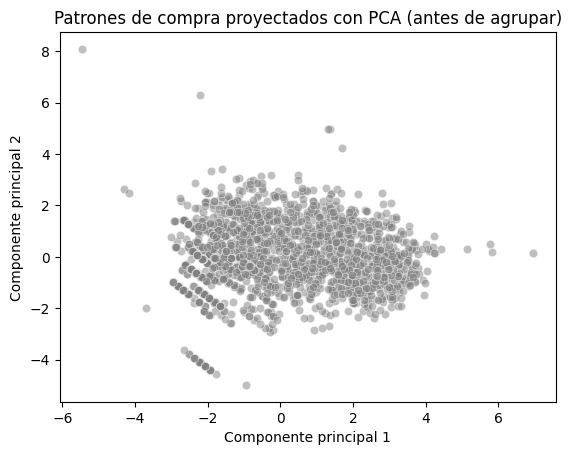

In [35]:

pca_rfm = PCA(n_components=2)                                                # 2 componentes para graficar
rfm_pca = pca_rfm.fit_transform(rfm_s)
print("Varianza explicada por PC1 + PC2: {:.2%}".format(pca_rfm.explained_variance_ratio_.sum()))
display(pd.DataFrame(pca_rfm.components_.T, index=vars_rfm, columns=['PC1', 'PC2']).round(2))  # Cargas

sns.scatterplot(x=rfm_pca[:, 0], y=rfm_pca[:, 1], alpha=0.5, color='gray')
plt.title('Patrones de compra proyectados con PCA (antes de agrupar)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.show()

¿Qué observamos?

Las 2 componentes explican el 65.58 % de la varianza.
PC1 = “valor y catálogo vs. cazador de ofertas”: a la derecha pesan Gasto_Total (0.47), Compras_Total (0.45) y Pct_Catalogo (0.44); a la izquierda, Pct_Descuento (−0.39) y NumWebVisitsMonth (−0.36). Los clientes que más compran usan el catálogo y casi no buscan descuentos; los que compran poco navegan mucho la web y compran en oferta.
PC2 = “digital vs. tienda física”: arriba Pct_Web (0.67) y abajo Pct_Tienda (−0.60).
Recency casi no pesa en ninguna (0.01): cuándo compró por última vez es independiente de cómo compra.
Se ven líneas diagonales y puntos aislados abajo a la izquierda: son clientes con muy pocas compras (1 o 2), cuyos porcentajes quedan en valores extremos como 0 % o 100 %.

## 5.3.2 Modelado

*Si es **agrupamiento**: elección de K con la silueta (lección 2.4), segundo método (jerárquico, lección 2.3, o DBSCAN, lección 2.5) y perfil de cada grupo en unidades originales con `groupby(...).mean()`.*

*Si es **clasificación**: kNN y árbol optimizados con `GridSearchCV`, Naive Bayes, y para cada modelo la matriz de confusión y la exactitud en los datos de **prueba** (lecciones 3.3 a 3.5).*

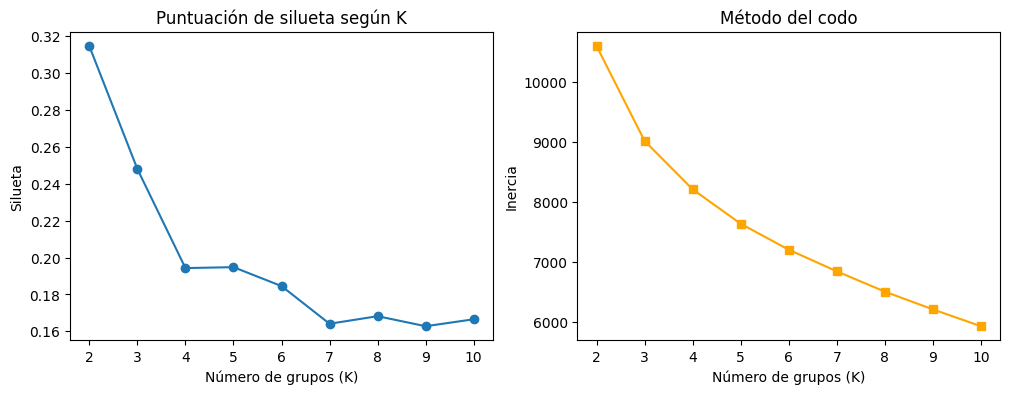

K = 2: silueta = 0.315
K = 3: silueta = 0.248
K = 4: silueta = 0.194
K = 5: silueta = 0.195
K = 6: silueta = 0.185
K = 7: silueta = 0.164
K = 8: silueta = 0.168
K = 9: silueta = 0.163
K = 10: silueta = 0.167


In [36]:
siluetas_rfm, inercias_rfm = [], []
for k in ks:                                                       # ks = range(2, 11), definido en el Área 2
    km_k = KMeans(n_clusters=k, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo con K grupos
    etiquetas = km_k.fit_predict(rfm_s)                            # Agrupa los patrones de compra
    siluetas_rfm.append(silhouette_score(rfm_s, etiquetas))        # Separación de los grupos
    inercias_rfm.append(km_k.inertia_)                             # Compacidad de los grupos

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, siluetas_rfm, 'o-')
axes[0].set_title('Puntuación de silueta según K')
axes[0].set_xlabel('Número de grupos (K)')
axes[0].set_ylabel('Silueta')
axes[1].plot(ks, inercias_rfm, 's-', color='orange')
axes[1].set_title('Método del codo')
axes[1].set_xlabel('Número de grupos (K)')
axes[1].set_ylabel('Inercia')
plt.show()

for k, s in zip(ks, siluetas_rfm):
    print("K = {}: silueta = {:.3f}".format(k, s))

¿Qué observamos? (elección de K)

La silueta más alta es K = 2 (0.315), pero dos patrones son muy pocos para decidir en qué canales invertir.
K = 3 tiene la mejor silueta entre las opciones útiles (0.248), muy por encima de K = 4 a 10 (0.16 a 0.19). El codo también se suaviza a partir de K = 3 o 4.
Decisión: K = 3. La silueta queda prácticamente en el umbral del criterio de éxito (0.25), así que los patrones tienen cierta superposición.

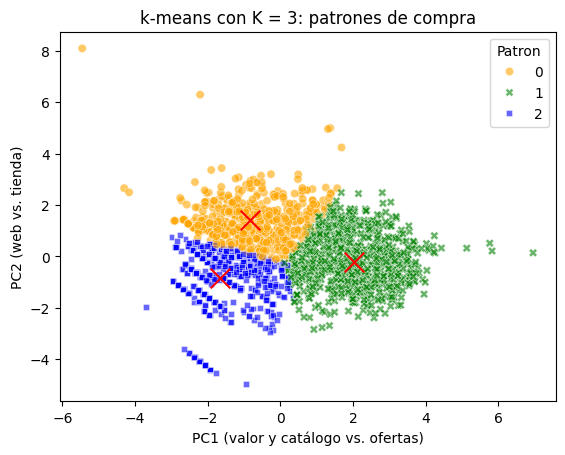

Patron,0,1,2
Recency,48.74,49.60,48.27
Compras_Total,11.48,19.29,5.74
Gasto_Total,359.55,1216.24,107.07
Pct_Web,0.46,0.28,0.29
Pct_Catalogo,0.13,0.28,0.06
Pct_Tienda,0.40,0.44,0.65
Pct_Descuento,0.33,0.10,0.34
NumWebVisitsMonth,7.22,3.48,5.97
Response,0.18,0.22,0.06
Clientes,536.00,792.00,697.00


In [37]:
# k-means final y perfil de los patrones

km_rfm = KMeans(n_clusters=3, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo final del Área 3
df_limpio['Patron'] = km_rfm.fit_predict(rfm_s)                    # Patrón de compra de cada cliente
centros_rfm = pca_rfm.transform(km_rfm.cluster_centers_)           # Centroides en el plano del PCA

sns.scatterplot(x=rfm_pca[:, 0], y=rfm_pca[:, 1], hue=df_limpio['Patron'], style=df_limpio['Patron'],
                palette=['orange', 'green', 'blue'], alpha=0.6)
plt.scatter(centros_rfm[:, 0], centros_rfm[:, 1], marker='x', s=200, c='red')    # Centroides
plt.title('k-means con K = 3: patrones de compra')
plt.xlabel('PC1 (valor y catálogo vs. ofertas)')
plt.ylabel('PC2 (web vs. tienda)')
plt.show()

perfil_rfm = df_limpio.groupby('Patron')[vars_rfm + ['Response']].mean().round(2)   # Promedios en unidades originales
perfil_rfm['Clientes'] = df_limpio['Patron'].value_counts().sort_index()
perfil_rfm['% del total'] = (perfil_rfm['Clientes'] / len(df_limpio) * 100).round(1)
perfil_rfm.T                                                       # Volteada para leerla completa

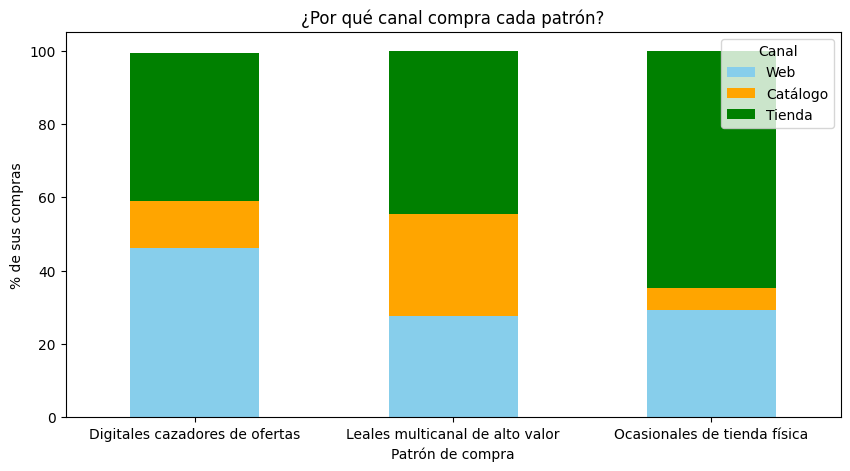

In [38]:
# nombres comerciales y gráfico de canales

nombres_rfm = {0: 'Digitales cazadores de ofertas', 1: 'Leales multicanal de alto valor', 2: 'Ocasionales de tienda física'}
df_limpio['Nombre_Patron'] = df_limpio['Patron'].map(nombres_rfm)          # Nombre comercial de cada cliente
perfil_rfm.index = perfil_rfm.index.map(nombres_rfm)                        # Nombres en la tabla de perfiles

canal = df_limpio.groupby('Nombre_Patron')[['Pct_Web', 'Pct_Catalogo', 'Pct_Tienda']].mean() * 100  # % por canal
canal.plot(kind='bar', stacked=True, figsize=(10, 5), color=['skyblue', 'orange', 'green'])        # Barras apiladas al 100 %
plt.title('¿Por qué canal compra cada patrón?')
plt.xlabel('Patrón de compra')
plt.ylabel('% de sus compras')
plt.xticks(rotation=0)
plt.legend(['Web', 'Catálogo', 'Tienda'], title='Canal')
plt.show()

¿Qué observamos? Los Digitales cazadores de ofertas hacen casi la mitad de sus compras por web (46 %). Los Leales multicanal reparten sus compras entre los 3 canales y son los que más usan el catálogo (28 %). Los Ocasionales de tienda física compran sobre todo en tienda (65 %) y casi nunca por catálogo (6 %).

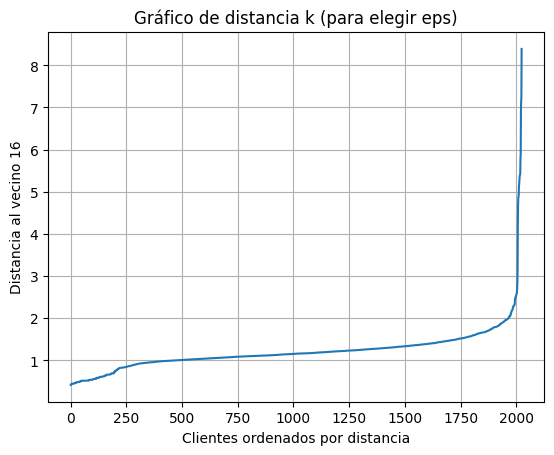

In [39]:
# DBSCAN (segundo método)

from sklearn.neighbors import NearestNeighbors        # Para calcular distancias a los vecinos
from sklearn.cluster import DBSCAN                    # Agrupamiento por densidad

min_muestras = 2 * rfm_s.shape[1]                     # Regla práctica: 2 × número de variables = 16
vecinos = NearestNeighbors(n_neighbors=min_muestras).fit(rfm_s)
distancias, _ = vecinos.kneighbors(rfm_s)             # Distancia de cada cliente a sus 16 vecinos más cercanos
dist_k = np.sort(distancias[:, -1])                   # Distancia al vecino 16, ordenada de menor a mayor

plt.plot(dist_k)
plt.title('Gráfico de distancia k (para elegir eps)')
plt.xlabel('Clientes ordenados por distancia')
plt.ylabel('Distancia al vecino 16')
plt.grid(True)
plt.show()

se mantiene plana hasta cerca del cliente 1950 y se dispara alrededor de distancia = 2. Ese es el codo, así que usamos eps = 2.0.

Grupos encontrados por DBSCAN (-1 = ruido):
DBSCAN
-1      25
 0    1976
 1      24
Name: count, dtype: int64


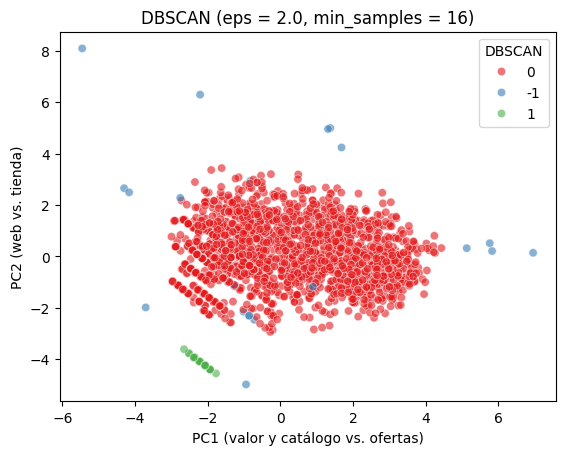

DBSCAN,-1,0,1
k-means,,,
Digitales cazadores de ofertas,11,525,0
Leales multicanal de alto valor,7,785,0
Ocasionales de tienda física,7,666,24


Recency               44.68
Compras_Total          9.24
Gasto_Total          467.52
Pct_Web                0.23
Pct_Catalogo           0.28
Pct_Tienda             0.26
Pct_Descuento          0.34
NumWebVisitsMonth      8.08
dtype: float64

In [40]:
# DBSCAN y compararlo con k-means.

dbscan = DBSCAN(eps=2.0, min_samples=min_muestras)               # eps tomado del codo de la curva
df_limpio['DBSCAN'] = dbscan.fit_predict(rfm_s)                   # -1 = ruido (cliente atípico)
print("Grupos encontrados por DBSCAN (-1 = ruido):")
print(df_limpio['DBSCAN'].value_counts().sort_index())

sns.scatterplot(x=rfm_pca[:, 0], y=rfm_pca[:, 1], hue=df_limpio['DBSCAN'].astype(str),
                palette='Set1', alpha=0.6)                        # Ruido y grupos de DBSCAN
plt.title('DBSCAN (eps = 2.0, min_samples = 16)')
plt.xlabel('PC1 (valor y catálogo vs. ofertas)')
plt.ylabel('PC2 (web vs. tienda)')
plt.show()

display(pd.crosstab(df_limpio['Nombre_Patron'], df_limpio['DBSCAN'],
                    rownames=['k-means'], colnames=['DBSCAN']))  # Cómo se reparten los patrones de k-means
df_limpio[df_limpio['DBSCAN'] == -1][vars_rfm].mean().round(2)    # Perfil promedio de los clientes atípicos


¿Qué observamos? (k-means vs DBSCAN)

DBSCAN pone al 97.6 % de los clientes (1976) en un solo grupo denso. Los patrones de compra no forman islas separadas sino una nube continua, y eso explica la silueta moderada de k-means (0.248).
k-means divide esa nube en 3 patrones útiles para decidir canales. DBSCAN, en cambio, sirve para detectar lo raro:
25 clientes atípicos (ruido): salen de los 3 patrones (11, 7 y 7). Tienen un comportamiento mezclado: visitan mucho la web (8 visitas al mes), usan bastante el catálogo (28 %) y compran con descuento (34 %).
Un micro nicho de 24 clientes, todos Ocasionales de tienda física, ubicados abajo en el eje web vs. tienda. Son clientes de comportamiento muy parecido, concentrado en la tienda física.
Conclusión: k-means es el método principal para la estrategia de canales, y DBSCAN lo complementa marcando los clientes que conviene revisar por separado.

## 5.3.3 Interpretación para el negocio

*¿Qué responde este resultado a la pregunta de negocio? ¿Qué decisión recomiendan? ¿Qué error es más costoso?*

Respuesta a la pregunta: hay 3 patrones de compra que se diferencian por la frecuencia, el monto y el canal (no por la recencia, que es igual en todos, unos 49 días).

Recomendación por patrón:

Leales multicanal de alto valor (39 %, gasto 1 216, aceptan campañas el 22 %): son el motor de las ventas y usan mucho el catálogo. Conviene mantener e invertir en el catálogo y en un programa de fidelidad. No darles descuentos (solo el 10 % de sus compras son en oferta): comprarían igual, y el descuento sería margen perdido.
Digitales cazadores de ofertas (27 %, 46 % por web, 7.2 visitas al mes): visitan mucho la web pero compran poco. Hay que llegarles con promociones por correo y ofertas en la web (ofertas relámpago, recordatorios del carrito) para convertir esas visitas en compras.
Ocasionales de tienda física (34 %, solo 5.7 compras, aceptan el 6 %): no conviene gastar en campañas telefónicas con ellos. Mejor promociones dentro de la tienda y una tarjeta de puntos que premie volver, para subir su frecuencia.
Los 25 clientes atípicos que marcó DBSCAN deben revisarse uno por uno antes de incluirlos en campañas.

Despliegue: cada mes se recalcula el patrón de cada cliente con km_rfm.predict() y el CRM lo etiqueta. El jefe de canales usa la etiqueta para decidir qué oferta y por qué canal enviarla.

Monitoreo: seguir mes a mes cuántos Ocasionales pasan a Leales (objetivo de la tarjeta de puntos) y la tasa de conversión web de los Digitales.

Limitaciones: la silueta (0.248) quedó justo debajo del 0.25 del criterio de éxito, por lo que este se cumple parcialmente: los patrones se superponen en sus bordes.

# 6. EVALUACIÓN Y CONCLUSIONES

*Comparen los resultados con los criterios de éxito de cada área y resuman las recomendaciones. Estas conclusiones deben coincidir con las del documento y las diapositivas.*

Resultados frente a los criterios de éxito

Área	Criterio de éxito	Resultado	¿Cumple?
1. Campañas (supervisada)	Detectar ≥ 60 % de los aceptantes y precisión > 15 %	Árbol: detecta el 68.8 % con precisión del 34.6 %	 Sí
2. Segmentación (no supervisada)	3 a 6 grupos, silueta > 0.25, perfiles distintos	3 segmentos, silueta 0.268	 Sí
3. Patrones de compra (no supervisada)	3 a 5 patrones, silueta > 0.25, diferencias en RFM o canal	3 patrones, silueta 0.248	 Parcial

Conclusiones integradas

Las 3 áreas apuntan al mismo hallazgo: un grupo reducido de clientes de alto valor sostiene el negocio. Los Premium sin hijos (22 % de los clientes) generan el 51 % de las ventas y aceptan el 28 % de las campañas, y los Leales multicanal son los que más compran y más responden.
Recomendación general: dejar de tratar a todos los clientes igual. Concentrar las campañas telefónicas en los que el árbol marca como “Acepta” (en su mayoría de estos grupos de alto valor), y atender a los grupos de bajo gasto con canales baratos (web, correo y promociones en tienda).
Llamar a todos genera pérdida (−801), mientras que usar el modelo genera ganancia y más del doble de tasa de aceptación.

Limitaciones generales: los datos son de 2012 a 2014 y no sabemos de qué país ni de qué empresa vienen. Los costos de contacto e ingreso (3 y 11) no están documentados. La clase está desbalanceada (15 %) y los grupos se superponen en sus bordes.

# REFERENCIAS

*Conjuntos de datos, notebooks y artículos consultados (formato APA), y herramientas de IA usadas.*

*-Patel, A. (2021). Customer Personality Analysis [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
*-Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C. y Wirth, R. (2000). CRISP-DM 1.0: Step-by-step data mining guide. SPSS Inc.
*-Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.
*-McKinney, W. (2010). Data structures for statistical computing in Python. Proceedings of the 9th Python in Science Conference, 56–61.
*-Waskom, M. L. (2021). seaborn: Statistical data visualization. Journal of Open Source Software, 6(60), 3021.
*-Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90–95.
*-Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261–272.
*-Lecciones del curso INF432: PCA, LDA, k-means, clustering jerárquico, DBSCAN y clasificación.

Uso de inteligencia artificial: se usó Claude (Anthropic) como asistente para guiar el desarrollo paso a paso, explicar el código y sugerir borradores de interpretación. Todo el código fue escrito, ejecutado y revisado por el grupo, y cada resultado fue verificado con las salidas del notebook